# Full Analysis — Misinformation, Political Threats & Defamation on Social Media

**Social Media Mining (Level 300) — semester project.** This notebook is the executed, end-to-end record of every analysis reported in the paper. It runs top to bottom on a plain Python environment (pandas, scikit-learn, scipy, matplotlib) with no API keys and no GPU.

**What is analysed**

| Leg | Data (in `data/`) | Analyses |
|---|---|---|
| Misinformation | FakeNewsNet / PolitiFact (432 fake, 624 real stories) | cascade-size tests incl. zero-inflation sensitivity, TF-IDF classifiers (hold-out + 5-fold CV), joint classifier-confidence x reach analysis |
| Political threats / hostility | Grimminger & Klinger (2021), 2020 US election (3,000 tweets) | hate classifier (with majority-class baseline + bootstrap CI), stance x hostility tests with odds ratios and multiple-comparison correction |
| Supplementary | Davidson et al. (2017) hate-speech corpus | political-keyword subset comparison |
| Defamation | no open English dataset exists | literature-only (see paper) |

Not executed here (require external network / GPU, see README): DistilBERT fine-tuning and UPFD propagation-graph analysis.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

warnings.filterwarnings('ignore')
ROOT = Path('..') if Path('../data').exists() else Path('.')
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
R = {}   # everything reported in the paper is collected here and saved at the end

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
C_FAKE, C_REAL, C_AGAINST, C_FAVOR = '#C0392B', '#2E6F9E', '#C0392B', '#2E6F9E'

def rank_biserial(x, y):
    # positive => x tends to be larger than y
    u = stats.mannwhitneyu(x, y, alternative='two-sided').statistic
    return 2 * u / (len(x) * len(y)) - 1

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def odds_ratio(a, b, c, d):
    # 2x2 [[a,b],[c,d]] ; Woolf 95% CI
    a, b, c, d = [x + 0.5 if 0 in (a, b, c, d) else x for x in (a, b, c, d)]
    orr = (a * d) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    return orr, np.exp(np.log(orr) - 1.96 * se), np.exp(np.log(orr) + 1.96 * se)
print('environment ready; root =', ROOT.resolve())

environment ready; root = /mnt/user-data/outputs


## 1. Misinformation leg — FakeNewsNet / PolitiFact

### 1.1 Data and the zero-tweet issue
`cascade_size` = number of tweet IDs FakeNewsNet recorded for a story (a diffusion-reach proxy). Many stories have **zero** recorded tweets, so we analyse reach in two parts: (a) *does the story have any tweets at all*, and (b) *among stories with tweets, how large is the cascade*.

In [2]:
mis = pd.read_csv(ROOT / 'data/processed_politifact.csv')
mis['has_tweets'] = mis['cascade_size'] > 0
fake, real = mis[mis.label == 1], mis[mis.label == 0]
print(f'stories: {len(mis)}  (fake={len(fake)}, real={len(real)})')

# --- (a) presence of any tweets
tab = pd.crosstab(mis.label.map({1: 'fake', 0: 'real'}), mis.has_tweets)
chi2, p_pres, _, _ = stats.chi2_contingency(tab)
or_, lo, hi = odds_ratio(int(tab.loc['fake', True]), int(tab.loc['fake', False]),
                         int(tab.loc['real', True]), int(tab.loc['real', False]))
share_fake, share_real = fake.has_tweets.mean(), real.has_tweets.mean()
print('\n(a) share of stories with >=1 tweet: fake %.1f%%  real %.1f%%' % (100*share_fake, 100*share_real))
print('    chi2=%.2f p=%.3g  odds ratio=%.2f (95%% CI %.2f-%.2f)' % (chi2, p_pres, or_, lo, hi))

# --- (b) magnitude, all stories vs only stories with tweets
u_all = stats.mannwhitneyu(fake.cascade_size, real.cascade_size, alternative='two-sided')
rb_all = rank_biserial(fake.cascade_size, real.cascade_size)
fz, rz = fake[fake.has_tweets].cascade_size, real[real.has_tweets].cascade_size
u_nz = stats.mannwhitneyu(fz, rz, alternative='two-sided')
rb_nz = rank_biserial(fz, rz)

# bootstrap CI for difference in medians (stories with tweets)
diffs = [np.median(rng.choice(fz, len(fz))) - np.median(rng.choice(rz, len(rz))) for _ in range(5000)]
ci_nz = np.percentile(diffs, [2.5, 97.5])
print('\n(b) ALL stories      : median fake=%d real=%d | U p=%.3g | rank-biserial=%.3f' %
      (fake.cascade_size.median(), real.cascade_size.median(), u_all.pvalue, rb_all))
print('    ONLY with tweets  : median fake=%d real=%d | U p=%.3f | rank-biserial=%.3f | median diff 95%% CI [%.0f, %.0f]' %
      (fz.median(), rz.median(), u_nz.pvalue, rb_nz, *ci_nz))

R['misinformation_reach'] = dict(
    n_fake=len(fake), n_real=len(real),
    share_with_tweets_fake=share_fake, share_with_tweets_real=share_real,
    n_zero_fake=int((~fake.has_tweets).sum()), n_zero_real=int((~real.has_tweets).sum()),
    presence_chi2=chi2, presence_p=p_pres, presence_odds_ratio=or_, presence_or_ci=[lo, hi],
    all_median_fake=float(fake.cascade_size.median()), all_median_real=float(real.cascade_size.median()),
    all_mwu_p=float(u_all.pvalue), all_rank_biserial=rb_all,
    nz_n_fake=len(fz), nz_n_real=len(rz),
    nz_median_fake=float(fz.median()), nz_median_real=float(rz.median()),
    nz_mwu_p=float(u_nz.pvalue), nz_rank_biserial=rb_nz, nz_median_diff_ci=[float(ci_nz[0]), float(ci_nz[1])])

stories: 1056  (fake=432, real=624)

(a) share of stories with >=1 tweet: fake 90.7%  real 65.5%
    chi2=87.10 p=1.03e-20  odds ratio=5.15 (95% CI 3.58-7.42)



(b) ALL stories      : median fake=79 real=8 | U p=7.7e-14 | rank-biserial=0.268
    ONLY with tweets  : median fake=102 real=58 | U p=0.500 | rank-biserial=0.028 | median diff 95% CI [7, 74]


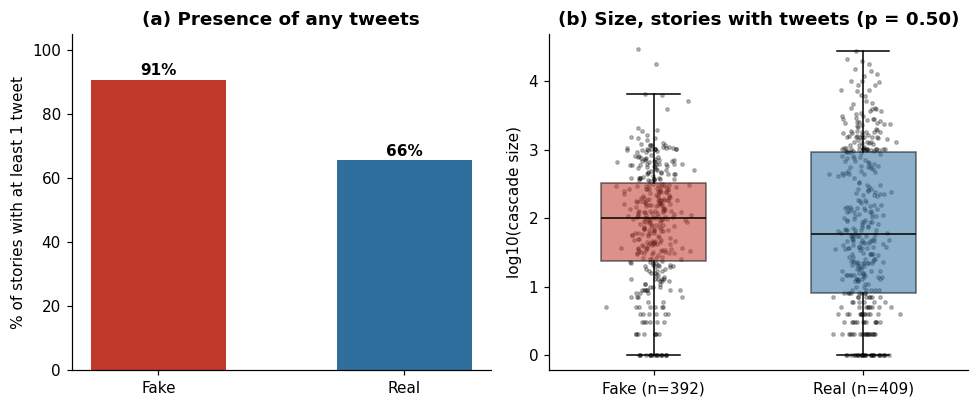

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
vals = [100*share_fake, 100*share_real]
b = ax[0].bar(['Fake', 'Real'], vals, color=[C_FAKE, C_REAL], width=.55)
for r_, v in zip(b, vals): ax[0].text(r_.get_x()+r_.get_width()/2, v+1.5, f'{v:.0f}%', ha='center', fontweight='bold')
ax[0].set_ylim(0, 105); ax[0].set_ylabel('% of stories with at least 1 tweet')
ax[0].set_title('(a) Presence of any tweets')

data = [np.log10(fz), np.log10(rz)]
bp = ax[1].boxplot(data, widths=.5, patch_artist=True, showfliers=False)
for patch, col in zip(bp['boxes'], [C_FAKE, C_REAL]): patch.set_facecolor(col); patch.set_alpha(.55)
for m in bp['medians']: m.set_color('black')
for i, d in enumerate(data, 1):
    ax[1].scatter(rng.normal(i, .06, len(d)), d, s=5, alpha=.25, color='k')
ax[1].set_xticklabels([f'Fake (n={len(fz)})', f'Real (n={len(rz)})'])
ax[1].set_ylabel('log10(cascade size)'); ax[1].set_title(f'(b) Size, stories with tweets (p = {u_nz.pvalue:.2f})')
plt.tight_layout(); plt.savefig(FIG / 'fig1_cascade_reach.png', dpi=200); plt.show()

### 1.2 Text classification of story titles (fake vs real)
TF-IDF (1-2 grams, 5,000 features) + Logistic Regression / Linear SVM. We report the fixed 80/20 hold-out used throughout the project **and** 5-fold stratified cross-validation, since ~1,000 stories make a single split noisy.

In [4]:
X, y = mis['title'].astype(str), mis['label']
Xtr, Xte, ytr, yte, itr, ite = train_test_split(X, y, mis.index, test_size=.2, random_state=SEED, stratify=y)
def make(model): return Pipeline([('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))), ('clf', model)])
models = {'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
          'Linear SVM': LinearSVC(class_weight='balanced', max_iter=3000)}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
maj = max(yte.mean(), 1 - yte.mean())
print(f'majority-class accuracy on hold-out = {maj:.3f}\n')
R['misinformation_classifier'] = {'majority_baseline_acc': maj}
for name, m in models.items():
    pipe = make(m).fit(Xtr, ytr); pr = pipe.predict(Xte)
    cvres = cross_validate(make(m), X, y, cv=cv, scoring=['accuracy', 'f1'])
    row = dict(holdout_acc=accuracy_score(yte, pr), holdout_f1=f1_score(yte, pr),
               holdout_precision=precision_score(yte, pr), holdout_recall=recall_score(yte, pr),
               cv_acc_mean=cvres['test_accuracy'].mean(), cv_acc_sd=cvres['test_accuracy'].std(),
               cv_f1_mean=cvres['test_f1'].mean(), cv_f1_sd=cvres['test_f1'].std())
    R['misinformation_classifier'][name] = row
    print(f"{name:20s} hold-out acc={row['holdout_acc']:.3f} F1={row['holdout_f1']:.3f} | "
          f"5-fold acc={row['cv_acc_mean']:.3f}+/-{row['cv_acc_sd']:.3f} F1={row['cv_f1_mean']:.3f}+/-{row['cv_f1_sd']:.3f}")

majority-class accuracy on hold-out = 0.590

Logistic Regression  hold-out acc=0.863 F1=0.842 | 5-fold acc=0.831+/-0.025 F1=0.795+/-0.036


Linear SVM           hold-out acc=0.877 F1=0.854 | 5-fold acc=0.833+/-0.014 F1=0.793+/-0.021


In [5]:
# What does the classifier actually key on? (interpretability / artifact check)
pipe = make(LogisticRegression(max_iter=1000, class_weight='balanced')).fit(X, y)
names = np.array(pipe['tfidf'].get_feature_names_out()); coef = pipe['clf'].coef_[0]
top_fake, top_real = names[np.argsort(coef)[-15:][::-1]], names[np.argsort(coef)[:15]]
print('Strongest FAKE-indicating terms:', ', '.join(top_fake))
print('Strongest REAL-indicating terms:', ', '.join(top_real))
R['misinformation_top_terms'] = {'fake': top_fake.tolist(), 'real': top_real.tolist()}

Strongest FAKE-indicating terms: trump, breaking, just, arrested, killed, million, michelle, dead, com, alabama, 2017, official, muslim, suspended, man
Strongest REAL-indicating terms: transcript, remarks, transcripts, debate, ad, mccain, senate, interview, action, care, health, remarks president, week transcript, act, political


### 1.3 Joint analysis — does classifier confidence relate to reach?
We obtain **out-of-fold** P(fake) for every story (calibrated SVM, 5-fold) so each story is scored by a model that never saw it, then correlate with cascade size (Spearman). We also repeat the original hold-out-only version used earlier in the project.

In [6]:
cal = Pipeline([('tfidf', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))),
                ('clf', CalibratedClassifierCV(LinearSVC(class_weight='balanced', max_iter=3000), cv=5))])
mis['p_fake_oof'] = cross_val_predict(cal, X, y, cv=cv, method='predict_proba')[:, 1]

def sp(d, label):
    rho, p = stats.spearmanr(d.p_fake_oof, d.cascade_size); print(f'{label:42s} rho={rho:.3f}  p={p:.3g}  n={len(d)}'); return dict(rho=float(rho), p=float(p), n=len(d))
R['joint'] = {
    'all_stories_oof':           sp(mis, 'All stories (out-of-fold)'),
    'stories_with_tweets_oof':   sp(mis[mis.has_tweets], 'Only stories with tweets'),
    'fake_with_tweets_oof':      sp(mis[(mis.label == 1) & mis.has_tweets], 'Fake stories with tweets'),
    'real_with_tweets_oof':      sp(mis[(mis.label == 0) & mis.has_tweets], 'Real stories with tweets')}

All stories (out-of-fold)                  rho=0.200  p=5.71e-11  n=1056
Only stories with tweets                   rho=0.050  p=0.157  n=801
Fake stories with tweets                   rho=0.068  p=0.182  n=392
Real stories with tweets                   rho=0.028  p=0.572  n=409


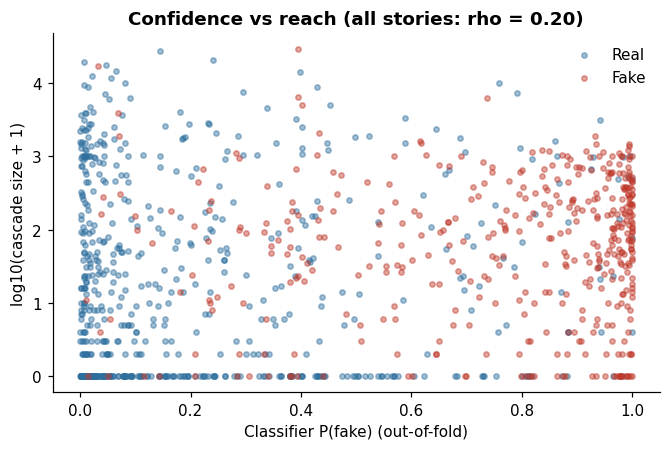

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for lab, col, nm in [(0, C_REAL, 'Real'), (1, C_FAKE, 'Fake')]:
    d = mis[mis.label == lab]
    ax.scatter(d.p_fake_oof, np.log10(d.cascade_size + 1), s=12, alpha=.45, color=col, label=nm)
ax.set_xlabel('Classifier P(fake) (out-of-fold)'); ax.set_ylabel('log10(cascade size + 1)')
j = R['joint']['all_stories_oof']; ax.set_title(f"Confidence vs reach (all stories: rho = {j['rho']:.2f})")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / 'fig2_confidence_vs_reach.png', dpi=200); plt.show()

## 2. Political-hostility leg — Grimminger & Klinger (2021)
3,000 tweets (provided 2,400 / 600 split) about the 2020 US election, annotated for stance toward Trump / Biden / West and for hateful-offensive speech (HOF).

### 2.1 Hate / offensive speech classifier

In [8]:
tr = pd.read_csv(ROOT / 'data/gk_train.tsv', sep='\t'); te = pd.read_csv(ROOT / 'data/gk_test.tsv', sep='\t')
for d in (tr, te): d['text'] = d['text'].str.replace('[NEWLINE]', ' ', regex=False)
ytr_g, yte_g = (tr.HOF == 'Hateful').astype(int), (te.HOF == 'Hateful').astype(int)
maj_g = 1 - yte_g.mean()
print(f'hateful share: train {ytr_g.mean():.1%}, test {yte_g.mean():.1%}  | majority-class accuracy on test = {maj_g:.3f}\n')
R['gk_classifier'] = {'majority_baseline_acc': float(maj_g), 'hateful_share_train': float(ytr_g.mean()), 'hateful_share_test': float(yte_g.mean())}
preds_store = {}
for name, m in models.items():
    pipe = make(m).fit(tr.text, ytr_g); pr = pipe.predict(te.text); preds_store[name] = pr
    f1 = f1_score(yte_g, pr)
    boots = []
    for _ in range(2000):
        ix = rng.integers(0, len(pr), len(pr)); boots.append(f1_score(yte_g.values[ix], pr[ix]))
    ci = np.percentile(boots, [2.5, 97.5])
    row = dict(acc=accuracy_score(yte_g, pr), f1_hateful=f1, f1_hateful_ci=[float(ci[0]), float(ci[1])],
               precision_hateful=precision_score(yte_g, pr), recall_hateful=recall_score(yte_g, pr),
               macro_f1=f1_score(yte_g, pr, average='macro'))
    R['gk_classifier'][name] = row
    print(f"{name:20s} acc={row['acc']:.3f} (majority={maj_g:.3f}) | Hateful: P={row['precision_hateful']:.2f} R={row['recall_hateful']:.2f} F1={f1:.3f} [95% CI {ci[0]:.2f}-{ci[1]:.2f}] | macro-F1={row['macro_f1']:.3f}")

hateful share: train 12.2%, test 9.8%  | majority-class accuracy on test = 0.902



Logistic Regression  acc=0.865 (majority=0.902) | Hateful: P=0.32 R=0.32 F1=0.319 [95% CI 0.20-0.42] | macro-F1=0.622


Linear SVM           acc=0.888 (majority=0.902) | Hateful: P=0.42 R=0.37 F1=0.396 [95% CI 0.28-0.51] | macro-F1=0.667


In [9]:
pipe = make(LogisticRegression(max_iter=1000, class_weight='balanced')).fit(pd.concat([tr.text, te.text]), pd.concat([ytr_g, yte_g]))
names = np.array(pipe['tfidf'].get_feature_names_out()); coef = pipe['clf'].coef_[0]
top_h = names[np.argsort(coef)[-20:][::-1]]
print('Strongest HATEFUL-indicating terms:', ', '.join(top_h))
R['gk_top_terms_hateful'] = top_h.tolist()

Strongest HATEFUL-indicating terms: trumpisanationaldisgrace, fuck, sleepy, fucking, moron, idiot, sleepy joe, fucktrump, ass, trumpcrimefamily, bullshit, shit, idiots, disgusting, pos, bitch, motherfucker, bs, ck, creepy joe


### 2.2 Does opposition concentrate hostility? (stance x HOF)
For each candidate, hateful-speech rate among tweets **Against** vs **Favor**. 2x2 chi-square (Yates), odds ratio with Woolf 95% CI, Bonferroni correction for the two tested candidates (alpha = 0.025). West is excluded (n = 6).

In [10]:
gk = pd.concat([tr, te], ignore_index=True); gk['hate'] = gk.HOF == 'Hateful'
rows = {}
for tgt in ['Trump', 'Biden']:
    a, f_ = gk[gk[tgt] == 'Against'], gk[gk[tgt] == 'Favor']
    ka, kf = int(a.hate.sum()), int(f_.hate.sum())
    tab = np.array([[ka, len(a) - ka], [kf, len(f_) - kf]])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    orr, lo, hi = odds_ratio(ka, len(a) - ka, kf, len(f_) - kf)
    rows[tgt] = dict(n_against=len(a), n_favor=len(f_), rate_against=ka/len(a), rate_favor=kf/len(f_),
                     ci_against=list(wilson(ka, len(a))), ci_favor=list(wilson(kf, len(f_))),
                     chi2=chi2, p=p, p_bonferroni=min(1, p*2), odds_ratio=orr, or_ci=[lo, hi])
    print(f'{tgt}: Against {ka}/{len(a)} = {ka/len(a):.1%} | Favor {kf}/{len(f_)} = {kf/len(f_):.1%} | chi2={chi2:.2f} p={p:.2g} (Bonf. p={min(1,p*2):.2g}) | OR={orr:.2f} [{lo:.2f}-{hi:.2f}]')
# Is hostility toward Biden-opponents higher than toward Trump-opponents?
aT, aB = gk[gk.Trump == 'Against'], gk[gk.Biden == 'Against']
tab = np.array([[aT.hate.sum(), len(aT)-aT.hate.sum()], [aB.hate.sum(), len(aB)-aB.hate.sum()]])
chi2, p, _, _ = stats.chi2_contingency(tab)
print(f'\nAgainst-Trump {aT.hate.mean():.1%} vs Against-Biden {aB.hate.mean():.1%}: chi2={chi2:.2f}, p={p:.3g}')
R['gk_stance'] = rows; R['gk_against_trump_vs_biden'] = dict(rate_trump=float(aT.hate.mean()), rate_biden=float(aB.hate.mean()), chi2=float(chi2), p=float(p))
R['gk_overall_hate_rate'] = float(gk.hate.mean()); R['gk_n'] = len(gk)

Trump: Against 156/842 = 18.5% | Favor 101/780 = 12.9% | chi2=9.04 p=0.0026 (Bonf. p=0.0053) | OR=1.53 [1.16-2.01]
Biden: Against 108/404 = 26.7% | Favor 141/1236 = 11.4% | chi2=54.34 p=1.7e-13 (Bonf. p=3.4e-13) | OR=2.83 [2.14-3.76]

Against-Trump 18.5% vs Against-Biden 26.7%: chi2=10.52, p=0.00118


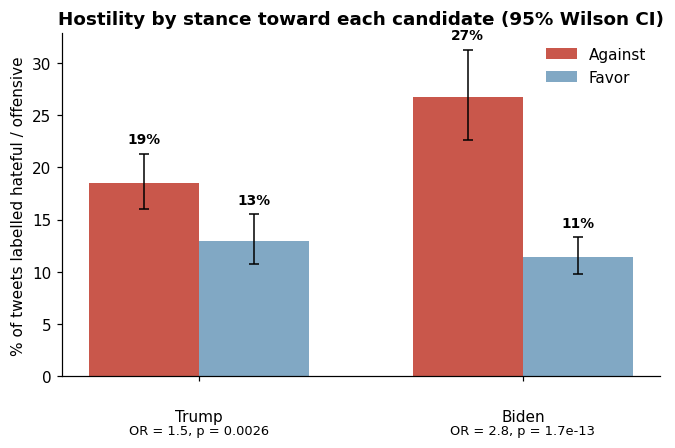

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 4.2)); w = .34
for i, tgt in enumerate(['Trump', 'Biden']):
    r_ = rows[tgt]
    for j, (k, col, lab) in enumerate([('against', C_AGAINST, 'Against'), ('favor', C_FAVOR, 'Favor')]):
        v, (lo, hi) = r_[f'rate_{k}'] * 100, [x*100 for x in r_[f'ci_{k}']]
        ax.bar(i + (j - .5) * w, v, w, color=col, alpha=.85 if j == 0 else .6, label=lab if i == 0 else None)
        ax.errorbar(i + (j - .5) * w, v, yerr=[[v-lo], [hi-v]], color='k', capsize=3, lw=1)
        ax.text(i + (j - .5) * w, hi + 1, f'{v:.0f}%', ha='center', fontsize=9, fontweight='bold')
    ax.text(i, -5.5, f"OR = {r_['odds_ratio']:.1f}, p = {r_['p']:.2g}", ha='center', fontsize=8.5)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Trump', 'Biden']); ax.tick_params(axis='x', pad=18)
ax.set_ylabel('% of tweets labelled hateful / offensive'); ax.set_title('Hostility by stance toward each candidate (95% Wilson CI)')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / 'fig3_stance_hostility.png', dpi=200); plt.show()

## 3. Supplementary — Davidson et al. (2017) keyword-filtered political subset
General hate-speech corpus (24,783 tweets). Political tweets are identified by keyword — a weak proxy kept only as a comparison to the purpose-built corpus above.

In [12]:
dv = pd.read_csv(ROOT / 'data/davidson_hate_speech.csv')
kw = 'trump|biden|obama|clinton|president|senator|congress|politician|government|gop|democrat|republican|election|vote|senate|mayor|governor|parliament|minister|potus|candidate'
dv['pol'] = dv.tweet.str.contains(kw, case=False, na=False); dv['hate'] = dv['class'] == 0
tab = pd.crosstab(dv.pol, dv.hate); chi2, p, _, _ = stats.chi2_contingency(tab)
print(tab, f"\npolitical hate rate {dv[dv.pol].hate.mean():.2%} vs other {dv[~dv.pol].hate.mean():.2%}; chi2={chi2:.2f}, p={p:.3f}")
R['davidson'] = dict(n=len(dv), n_political=int(dv.pol.sum()), rate_political=float(dv[dv.pol].hate.mean()), rate_other=float(dv[~dv.pol].hate.mean()), chi2=float(chi2), p=float(p))

hate   False  True 
pol                
False  23047   1404
True     306     26 
political hate rate 7.83% vs other 5.74%; chi2=2.26, p=0.133


## 4. Save all reported numbers

In [13]:
def clean(o):
    if isinstance(o, dict): return {k: clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(RES / 'full_analysis_results.json', 'w') as f: json.dump(clean(R), f, indent=2)
print('saved', RES / 'full_analysis_results.json'); print('figures:', sorted(p.name for p in FIG.glob('*.png')))

saved ../results/full_analysis_results.json
figures: ['fig1_cascade_reach.png', 'fig2_confidence_vs_reach.png', 'fig3_stance_hostility.png']
